# Entregable 1
## Análisis y preparación de homicidios
Integrantes: Liseth Simbaña, Oscar Lara y Anthony Pilamunga.

Ejecuta primero la parte A. La parte B prepara el 911 como apoyo y es opcional para esta actividad. No se entrenan modelos. Unificar archivos concatena registros; agregar por fecha y territorio reduce filas conservando los conteos. No se unen víctimas y emergencias individuales entre sí.

Los originales se conservan. Las salidas se guardan en una carpeta separada. Puedes ejecutar en Colab; hacerlo local requiere cambiar las rutas y omitir la conexión a Drive.

# Tema seleccionado
Se estudiarán los patrones espaciales y temporales de los homicidios intencionales en Ecuador. El proyecto propone relacionar sus registros históricos con los incidentes gestionados por el ECU 911 y con factores de calendario, como el día de la semana y los feriados. La unidad de análisis será cantón-día.

## Problemática y Referencias

Pregunta: ¿Cuántas víctimas de homicidio intencional se registrarían en un cantón el día siguiente, utilizando historia previa y calendario?

La fuente principal es Ministerio del Interior. ECU 911 aporta emergencias complementarias y la API aporta feriados. Una emergencia no equivale a un homicidio.

Referencias: https://www.datosabiertos.gob.ec/dataset/homicidios-intencionales ; https://www.datosabiertos.gob.ec/dataset/base-de-emergencias ; https://feriados.io/docs .

La unidad adoptada por el equipo es la víctima. Cada fila se contabiliza como una víctima registrada; varias pueden compartir características del hecho. Se debe incluir la referencia documental que respalda esta definición.

## Justificación problema y fuentes
La problemática tiene respaldo institucional. El ECU 911 informó que durante 2025 coordinó 3.239.683 emergencias, de las cuales 2.150.615 correspondieron a seguridad ciudadana. Su publicación también presenta diferencias entre cantones. Estas cifras justifican estudiar la distribución territorial de las emergencias y su posible utilidad como información complementaria; no constituyen el número de filas del archivo que utilizará el equipo ni equivalen a homicidios (Servicio Integrado de Seguridad ECU 911, 2026).

Asimismo, el Ministerio del Interior publica información estadística oficial de homicidios intencionales y reportó variaciones entre mayo de 2025 y mayo de 2026, aclarando el carácter preliminar del dato más reciente. Esto respalda la relevancia del fenómeno y la necesidad de documentar la versión y el corte de cada archivo antes de comparar periodos (Ministerio del Interior, 2026).

**Antecedentes e información disponible**

Existen registros administrativos de homicidios y de emergencias coordinadas, así como un proveedor de calendario que documenta soporte para Ecuador. Los documentos del equipo seleccionan estas fuentes para estudiar un problema territorial y temporal. Sin embargo, disponer de estadísticas oficiales no demuestra que los archivos concretos tengan cobertura completa a nivel cantón-día ni que la actividad del ECU 911 mejore una predicción.

**Aspecto por estudiar**

Se propone evaluar si los rezagos del conteo de homicidios, la actividad previa de emergencias y el calendario permiten describir patrones y, posteriormente, mejorar una estimación frente a una referencia simple. La relación entre ECU 911 y homicidios es una hipótesis de trabajo, no un resultado comprobado. Tampoco se asumirá que un feriado causa un aumento de violencia.

**Utilidad esperada**

Una respuesta permitiría contar con una base territorial y temporal reutilizable, un análisis transparente y, en etapas posteriores, estimaciones evaluadas para apoyar planificación. También sería útil concluir que una fuente no aporta capacidad predictiva o que su cobertura impide responder la pregunta: esas limitaciones orientan decisiones y evitan promesas sin evidencia.

### Características necesarias para el análisis

El dataset principal contiene registros de víctimas de homicidios intencionales. Para analizar su distribución por cantón y día, se consideran las siguientes características:

| Característica | Columnas relacionadas | ¿Qué representa? | ¿Por qué es útil? |
|---|---|---|---|
| Fecha de ocurrencia | fecha_infraccion | Fecha en la que ocurrió el hecho. | Permite ordenar los registros, contar víctimas por día y obtener variables de calendario. |
| Provincia | codigo_provincia, provincia | Provincia en la que ocurrió el hecho. | Permite identificar el territorio y comprobar la correspondencia con el cantón. |
| Cantón | codigo_canton, canton | Cantón en el que ocurrió el hecho. | Permite agrupar las víctimas territorialmente y relacionar posteriormente los datos con el ECU 911. |
| Tipo de muerte | tipo_muerte | Clasificación del homicidio registrada por la fuente. | Permite comprender las categorías incluidas y revisar su consistencia entre archivos. |
| Historial de víctimas | Conteo construido a partir de los registros | Número de víctimas registradas por cantón y día. | Permite definir la variable objetivo y construir información histórica para una futura etapa de Machine Learning. |
| Hora de ocurrencia | hora_infraccion | Hora en la que ocurrió el hecho. | Permite estudiar la distribución horaria de las víctimas. La hora del hecho futuro no se utilizará como entrada para predecir el total diario. |

Se revisarán los valores faltantes, los formatos de fecha, las categorías y la correspondencia entre códigos y nombres territoriales. Los códigos se conservarán como texto para mantener los ceros iniciales.

El conteo diario no es una columna original: se construirá agrupando los registros por fecha y territorio. Los atributos de las víctimas del día que se desea predecir, como edad, sexo o profesión, no se utilizarán como entradas del modelo porque se conocen después de ocurrido el hecho.

## Parte A Homicidios como fuente principal
### 1 Configuración y carga
Esta es la única lectura de los dos Excel. Si cambian sus nombres, edita las rutas. Una copia repetida no debe incorporarse nuevamente.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")
carpeta_homicidios = Path("/content/drive/MyDrive/Homicidios")
carpeta_911 = Path("/content/drive/MyDrive/BD911Homi")
carpeta_salida = Path("/content/drive/MyDrive/Resultados_911_Homicidios")
carpeta_salida.mkdir(parents=True, exist_ok=True)
archivo_historico = carpeta_homicidios / "mdi_homicidiosintencionales_pm_2014_2025.xlsx"
archivo_2026 = carpeta_homicidios / "mdi_homicidiosintencionales_pm_2026_enero_agosto.xlsx"
archivohistorio = pd.read_excel(archivo_historico, sheet_name="1. Homicidios Intencionales", dtype=str)
archivo2026homi = pd.read_excel(archivo_2026, sheet_name="1. Homicidios Intencionales", dtype=str)
for nombre, df in [("Histórico", archivohistorio), ("2026", archivo2026homi)]:
    print(nombre, df.shape)
    display(df.head())
    df.info()
if not archivohistorio.columns.equals(archivo2026homi.columns):
    raise ValueError("Revisa las diferencias de columnas antes de concatenar")


Mounted at /content/drive
Histórico (39821, 33)


,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
0,FEMICIDIO,ZONA 9,D.M. QUITO,QUITUMBE,TURUBAMBA,17D07C05S06,TURUBAMBA 6,17,PICHINCHA,1701,...,30,A,MUJER,FEMENINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
1,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVO GUAYAQUIL,09D08C06S01,NUEVO GUAYAQUIL 1,09,GUAYAS,0901,...,25,A,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
2,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVO GUAYAQUIL,09D08C06S01,NUEVO GUAYAQUIL 1,09,GUAYAS,0901,...,26,A,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
3,ASESINATO,ZONA 5,GUAYAS,EMPALME,EMPALME CENTRO,09D15C06S01,EMPALME CENTRO 1,09,GUAYAS,0908,...,21,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR GENERAL,SIN_DATO
4,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PORTETE,SUBURBIO,09D04C06S03,SUBURBIO 3,09,GUAYAS,0901,...,31,A,HOMBRE,MASCULINO,MESTIZO/A,DIVORCIADO,ECUADOR,NINGUNA,ESTADO PERSONAL,BACHILLERATO


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39821 entries, 0 to 39820
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   tipo_muerte               39821 non-null  object
 1   zona                      39821 non-null  object
 2   subzona                   39821 non-null  object
 3   distrito                  39821 non-null  object
 4   circuito                  39821 non-null  object
 5   codigo_subcircuito        39821 non-null  object
 6   subcircuito               39821 non-null  object
 7   codigo_provincia          39821 non-null  object
 8   provincia                 39821 non-null  object
 9   codigo_canton             39821 non-null  object
 10  canton                    39821 non-null  object
 11  coordenada_y              39821 non-null  object
 12  coordenada_x              39821 non-null  object
 13  area_hecho                39821 non-null  object
 14  lugar                 

,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
0,ASESINATO,ZONA 7,EL ORO,MACHALA,9 DE MAYO,07D02C01S01,9 DE MAYO 1,07,EL ORO,0701,...,33,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR GENERAL,SIN_DATO
1,ASESINATO,ZONA 1,ESMERALDAS,ESMERALDAS,AIRE LIBRE,08D01C03S01,AIRE LIBRE 1,08,ESMERALDAS,0801,...,50,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR GENERAL,SIN_DATO
2,ASESINATO,ZONA 8,D.M. GUAYAQUIL,FLORIDA,JUAN MONTALVO,09D06C04S04,JUAN MONTALVO 4,09,GUAYAS,0901,...,30,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,BACHILLER CIENCIAS,SIN_DATO
3,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PORTETE,PORTETE,09D04C04S04,PORTETE 4,09,GUAYAS,0901,...,48,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR PRIMARIO,SIN_DATO
4,ASESINATO,ZONA 1,IMBABURA,CIUDAD BLANCA,LAS LOMAS,10D01C09S01,LAS LOMAS 1,10,IMBABURA,1001,...,30,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,AYUDANTE/JORNALERO,BASICA


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5676 entries, 0 to 5675
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   tipo_muerte               5676 non-null   object
 1   zona                      5676 non-null   object
 2   subzona                   5676 non-null   object
 3   distrito                  5676 non-null   object
 4   circuito                  5676 non-null   object
 5   codigo_subcircuito        5676 non-null   object
 6   subcircuito               5676 non-null   object
 7   codigo_provincia          5676 non-null   object
 8   provincia                 5676 non-null   object
 9   codigo_canton             5676 non-null   object
 10  canton                    5676 non-null   object
 11  coordenada_y              5676 non-null   object
 12  coordenada_x              5676 non-null   object
 13  area_hecho                5676 non-null   object
 14  lugar                   

### 2 Procedencia y unidad de registro
Fuente principal: Ministerio del Interior DINASED. La hoja Contenido documenta cobertura y actualización; no confundir frecuencia de publicación con granularidad diaria. El equipo indica que la unidad es víctima. Varias víctimas pueden compartir fecha, hora y ubicación. No se reconstruyen sucesos únicos a partir de esos campos.

In [ ]:
for archivo in [archivo_historico, archivo_2026]:
    print("Metadatos:", archivo.name)
    display(pd.read_excel(archivo, sheet_name="Contenido", header=None).dropna(how="all"))

# Conservar originales y procedencia antes de unir
homicidios_originales = pd.concat([
    archivohistorio.assign(archivo_origen=archivo_historico.name),
    archivo2026homi.assign(archivo_origen=archivo_2026.name)
], ignore_index=True)
print("Total unificado:", homicidios_originales.shape)


Metadatos: mdi_homicidiosintencionales_pm_2014_2025.xlsx


,0,1,2
2,NaN,Campo,Valor
3,NaN,Conjunto de Datos,Estadísticas de homicidios intencionales.
4,NaN,Pestaña,1. Homicidios Intencionales
5,NaN,Elaborado por,Dirección de Estadística y Economía de la Segu...
6,NaN,Descripción,Este conjunto de datos contiene información es...
7,NaN,Periodo de cobertura,2014 a 2025
8,NaN,Fecha actualización,18 de septiembre de 2026.
9,NaN,Fecha publicación,18 de septiembre de 2026.
10,NaN,Frecuencia de actualizacion,Mensual.
11,NaN,Fuentes,Ministerio del Interior-DINASED. Estadística d...


Metadatos: mdi_homicidiosintencionales_pm_2026_enero_agosto.xlsx


,0,1,2
2,NaN,Campo,Valor
3,NaN,Conjunto de Datos,Estadísticas de homicidios intencionales.
4,NaN,Pestaña,1. Homicidios Intencionales
5,NaN,Elaborado por,Dirección de Estadística y Economía de la Segu...
6,NaN,Descripción,Este conjunto de datos contiene información es...
7,NaN,Periodo de cobertura,enero a agosto de 2026
8,NaN,Fecha actualización,18 de septiembre de 2026.
9,NaN,Fecha publicación,18 de septiembre de 2026.
10,NaN,Frecuencia de actualizacion,Mensual.
11,NaN,Fuentes,Ministerio del Interior-DINASED. Estadística d...


Total unificado: (45497, 34)


### 3 Exploración de faltantes y repetidos
No hay que borrar filas por faltantes en atributos opcionales. Los candidatos idénticos se conservan sin una clave individual que demuestre duplicación. Los conteos duplicados excluyen archivo_origen para comparar atributos de la fuente.

In [ ]:
for nombre, df in [("Histórico", archivohistorio), ("2026", archivo2026homi)]:
    print("\n", nombre)
    display(pd.DataFrame({"nulos": df.isna().sum(),
                          "SIN_DATO": df.eq("SIN_DATO").sum(),
                          "porcentaje_SIN_DATO": (df.eq("SIN_DATO").mean()*100).round(2)}))
    print("Repeticiones adicionales:", df.duplicated().sum())
    display(df.loc[df.duplicated(keep=False)].head(10))
    print("Categorías de tipo_muerte:")
    display(df.tipo_muerte.value_counts(dropna=False))
    print("Provincias:")
    display(df.provincia.value_counts(dropna=False))



 Histórico


,nulos,SIN_DATO,porcentaje_SIN_DATO
tipo_muerte,0,0,0.00
zona,0,0,0.00
subzona,0,0,0.00
distrito,0,0,0.00
circuito,0,0,0.00
codigo_subcircuito,0,0,0.00
subcircuito,0,0,0.00
codigo_provincia,0,0,0.00
provincia,0,0,0.00
codigo_canton,0,0,0.00


Repeticiones adicionales: 186


,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
137,ASESINATO,ZONA 4,MANABÍ,JIPIJAPA,PUERTO LÓPEZ,13D03C11S01,PUERTO LÓPEZ 1,13,MANABÍ,1319,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,OTROS,NINGUNA,SIN_DATO,SIN_DATO
138,ASESINATO,ZONA 4,MANABÍ,JIPIJAPA,PUERTO LÓPEZ,13D03C11S01,PUERTO LÓPEZ 1,13,MANABÍ,1319,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,OTROS,NINGUNA,SIN_DATO,SIN_DATO
380,ASESINATO,ZONA 7,EL ORO,PASAJE,RIO BONITO,07D01C06S01,RIO BONITO 1,07,EL ORO,0706,...,27,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,SIN_DATO
381,ASESINATO,ZONA 7,EL ORO,PASAJE,RIO BONITO,07D01C06S01,RIO BONITO 1,07,EL ORO,0706,...,27,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,SIN_DATO
436,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVA PROSPERINA,09D08C01S02,NUEVA PROSPERINA 2,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
437,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVA PROSPERINA,09D08C01S02,NUEVA PROSPERINA 2,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
438,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVA PROSPERINA,09D08C01S02,NUEVA PROSPERINA 2,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
613,ASESINATO,ZONA 7,EL ORO,MACHALA,GRAL SERRANO,07D02C06S01,GRAL SERRANO 1,07,EL ORO,0701,...,21,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,SIN_DATO
616,ASESINATO,ZONA 7,EL ORO,MACHALA,GRAL SERRANO,07D02C06S01,GRAL SERRANO 1,07,EL ORO,0701,...,21,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,SIN_DATO
632,ASESINATO,ZONA 8,D.M. GUAYAQUIL,FLORIDA,MAPASINGUE,09D06C06S02,MAPASINGUE 2,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO


Categorías de tipo_muerte:


...

,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
13,ASESINATO,ZONA 7,EL ORO,HUAQUILLAS,ARENILLAS,07D05C02S01,ARENILLAS 1,07,EL ORO,0702,...,28,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,BASICA
14,ASESINATO,ZONA 7,EL ORO,HUAQUILLAS,ARENILLAS,07D05C02S01,ARENILLAS 1,07,EL ORO,0702,...,28,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,BASICA
110,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PROGRESO,PROGRESO,09D10C03S01,PROGRESO 1,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
112,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PROGRESO,PROGRESO,09D10C03S01,PROGRESO 1,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
319,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PROGRESO,POSORJA,09D10C02S01,POSORJA 1,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
320,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PROGRESO,POSORJA,09D10C02S01,POSORJA 1,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
360,ASESINATO,ZONA 5,SANTA ELENA,SANTA ELENA,MANANTIAL,24D01C06S01,MANANTIAL DE GUANGALA 1,24,SANTA ELENA,2401,...,20,A,HOMBRE,MASCULINO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO
361,ASESINATO,ZONA 5,SANTA ELENA,SANTA ELENA,MANANTIAL,24D01C06S01,MANANTIAL DE GUANGALA 1,24,SANTA ELENA,2401,...,20,A,HOMBRE,MASCULINO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO
362,ASESINATO,ZONA 5,SANTA ELENA,SANTA ELENA,MANANTIAL,24D01C06S01,MANANTIAL DE GUANGALA 1,24,SANTA ELENA,2401,...,20,A,HOMBRE,MASCULINO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO
363,ASESINATO,ZONA 5,SANTA ELENA,SANTA ELENA,MANANTIAL,24D01C06S01,MANANTIAL DE GUANGALA 1,24,SANTA ELENA,2401,...,20,A,HOMBRE,MASCULINO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO


Categorías de tipo_muerte:


,count
tipo_muerte,
ASESINATO,5392
HOMICIDIO,217
FEMICIDIO,44
SICARIATO,23


Provincias:


,count
provincia,
GUAYAS,2340
MANABÍ,839
EL ORO,788
LOS RÍOS,629
ESMERALDAS,228
PICHINCHA,183
SANTA ELENA,169
SUCUMBÍOS,100
ORELLANA,77


### Interpretación de los valores faltantes

No se encontraron valores nulos reconocidos por pandas en ninguno de los
dos archivos. Sin embargo, existen valores `SIN_DATO` que representan
información no disponible.

Las columnas necesarias para identificar la fecha y el territorio no
presentan nulos ni valores `SIN_DATO` en esta revisión. Se verificará
posteriormente la validez de las fechas y la consistencia territorial.

Los valores desconocidos se concentran en características personales,
especialmente instrucción y profesión. No se eliminarán registros por
faltantes en estas columnas, porque cada fila representa una víctima y
estos atributos no son necesarios para construir el conteo diario por cantón.

La hora de infracción presenta cinco valores `SIN_DATO` en el histórico.
Estos registros se conservarán para el análisis diario y se excluirán
únicamente de los análisis que requieran una hora conocida.

### Interpretación de repetidos
En las salidas anteriores se identificaron 186 repeticiones adicionales en el histórico y 45 en 2026 con duplicated(). Se conservan porque los atributos publicados no constituyen una clave individual de víctima.

### 4 Limpieza justificada
Se convierten SIN_DATO y textos vacíos en faltantes, se normalizan espacios y mayúsculas territoriales y se convierten fechas. Se conservan los códigos como texto. Las filas sin fecha o territorio se separan y contabilizan; no se imputan. La hora se conserva para exploración.

In [ ]:
homicidios_limpios = homicidios_originales.copy()
homicidios_limpios = homicidios_limpios.replace(r"^\s*$", pd.NA, regex=True)
homicidios_limpios = homicidios_limpios.replace("SIN_DATO", pd.NA)
for columna in ["provincia", "canton", "tipo_muerte"]:
    homicidios_limpios[columna] = (homicidios_limpios[columna].astype("string")
                                  .str.strip().str.upper().str.replace(r"\s+", " ", regex=True))
for columna, longitud in [("codigo_provincia", 2), ("codigo_canton", 4)]:
    homicidios_limpios[columna] = homicidios_limpios[columna].astype("string").str.strip().str.zfill(longitud)
fechas = pd.to_datetime(homicidios_limpios.fecha_infraccion, format="mixed", dayfirst=True, errors="coerce")
print("Fechas no interpretables:", fechas.isna().sum())
display(homicidios_originales.loc[fechas.isna(), ["fecha_infraccion", "archivo_origen"]].head())
homicidios_limpios["fecha_infraccion"] = fechas.dt.normalize()
horas = pd.to_datetime(homicidios_limpios.hora_infraccion, format="%H:%M:%S", errors="coerce")
print("Horas no interpretables o desconocidas:", horas.isna().sum())
display(homicidios_limpios.loc[horas.isna(), ["hora_infraccion"]].drop_duplicates().head(20))
# No se elimina una víctima por falta de hora
homicidios_limpios["hora"] = horas.dt.hour
esenciales = ["fecha_infraccion", "provincia", "canton", "codigo_canton"]
invalidas = homicidios_limpios[esenciales].isna().any(axis=1)
rechazados = homicidios_limpios.loc[invalidas].copy()
homicidios_validos = homicidios_limpios.loc[~invalidas].copy()
print("Filas válidas:", len(homicidios_validos), "Separadas:", len(rechazados))
print("Cobertura real:", homicidios_validos.fecha_infraccion.min(), homicidios_validos.fecha_infraccion.max())
revision_territorio = homicidios_validos.groupby("codigo_canton").agg(
    nombres=("canton", "nunique"), provincias=("provincia", "nunique"))
display(revision_territorio.loc[(revision_territorio.nombres > 1) | (revision_territorio.provincias > 1)])


Fechas no interpretables: 0


,fecha_infraccion,archivo_origen


Horas no interpretables o desconocidas: 5


,hora_infraccion
33804,<NA>


Filas válidas: 45497 Separadas: 0
Cobertura real: 2014-01-01 00:00:00 2026-08-31 00:00:00


,nombres,provincias
codigo_canton,,


### 5 Comparación antes y después
La conversión de SIN_DATO aumenta los nulos reconocidos; no significa que se haya perdido información. Las estadísticas se comparan sobre las mismas columnas originales. Los cambios territoriales o valores extremos requieren revisión, no eliminación automática.

In [ ]:
columnas_originales = archivohistorio.columns.tolist()
antes = homicidios_originales[columnas_originales]
despues = homicidios_validos[columnas_originales]
comparacion = pd.DataFrame({
    "indicador": ["Registros", "Columnas originales", "Repeticiones adicionales",
                  "Nulos reconocidos", "Textos SIN_DATO"],
    "antes": [len(antes), len(antes.columns), antes.duplicated().sum(),
              antes.isna().sum().sum(), antes.eq("SIN_DATO").sum().sum()],
    "despues": [len(despues), len(despues.columns), despues.duplicated().sum(),
                despues.isna().sum().sum(), despues.eq("SIN_DATO").sum().sum()]})
display(comparacion)
display(pd.DataFrame({"nulos_antes": antes.isna().sum(), "nulos_despues": despues.isna().sum(),
                      "tipo_antes": antes.dtypes.astype(str), "tipo_despues": despues.dtypes.astype(str),
                      "categorias_antes": antes.nunique(), "categorias_despues": despues.nunique()}))


,indicador,antes,despues
0,Registros,45497,45497
1,Columnas originales,33,33
2,Repeticiones adicionales,231,231
3,Nulos reconocidos,0,58602
4,Textos SIN_DATO,58602,0


,nulos_antes,nulos_despues,tipo_antes,tipo_despues,categorias_antes,categorias_despues
tipo_muerte,0,0,object,string,4,4
zona,0,0,object,object,9,9
subzona,0,0,object,object,26,26
distrito,0,0,object,object,141,141
circuito,0,0,object,object,935,935
codigo_subcircuito,0,0,object,object,1752,1752
subcircuito,0,0,object,object,1616,1616
codigo_provincia,0,0,object,string,24,24
provincia,0,0,object,string,24,24
codigo_canton,0,0,object,string,216,216


### 6 Conteos y visualizaciones
Contamos víctimas por día observado y territorio. No se rellenan ceros todavía: un día sin filas puede requerir confirmación de cobertura. El histórico de 2026 es parcial. El ranking presenta conteos absolutos, no tasas de riesgo. Los días altos se investigan y no se descartan automáticamente.

,fecha_infraccion,codigo_provincia,provincia,codigo_canton,canton,victimas_homicidio
0,2014-01-01,01,AZUAY,0101,CUENCA,1
1,2014-01-01,02,BOLÍVAR,0201,GUARANDA,1
2,2014-01-01,04,CARCHI,0401,TULCÁN,2
3,2014-01-01,06,CHIMBORAZO,0601,RIOBAMBA,1
4,2014-01-01,07,EL ORO,0712,SANTA ROSA,1


,victimas_homicidio
count,27384.000000
mean,1.661445
std,1.907554
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,125.000000


,fecha_infraccion,codigo_provincia,provincia,codigo_canton,canton,victimas_homicidio
7883,2021-09-28,09,GUAYAS,0901,GUAYAQUIL,125
8101,2021-11-12,09,GUAYAS,0901,GUAYAQUIL,65
9224,2022-05-09,23,STO DGO DE LOS TSÁCHILAS,2301,SANTO DOMINGO,46
6934,2021-02-23,09,GUAYAS,0901,GUAYAQUIL,40
23555,2025-11-09,07,EL ORO,0701,MACHALA,38
6929,2021-02-23,01,AZUAY,0101,CUENCA,34
20335,2025-03-06,09,GUAYAS,0901,GUAYAQUIL,29
13485,2023-07-23,09,GUAYAS,0901,GUAYAQUIL,26
22281,2025-08-10,09,GUAYAS,0901,GUAYAQUIL,23
15645,2024-01-01,09,GUAYAS,0907,DURÁN,22


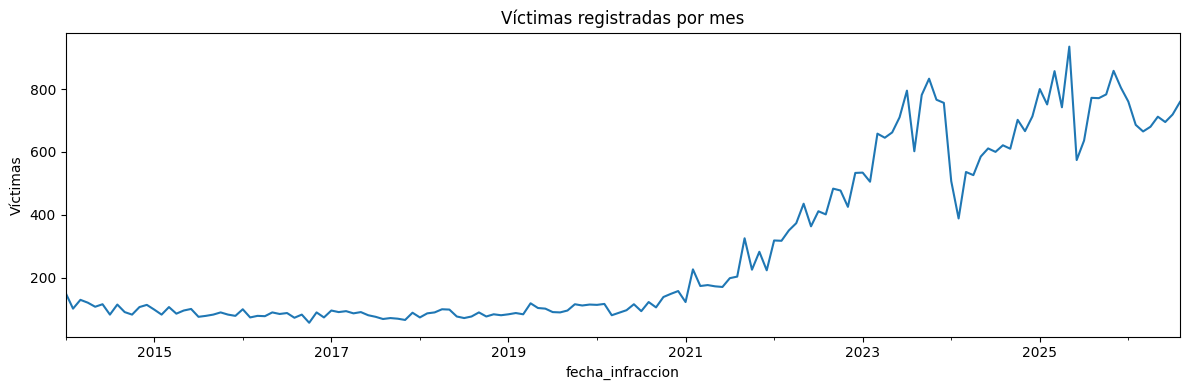

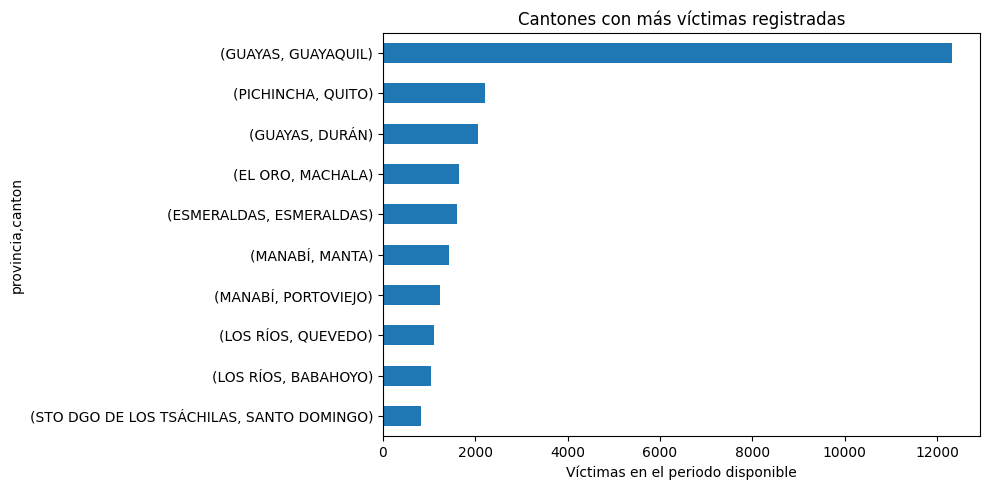

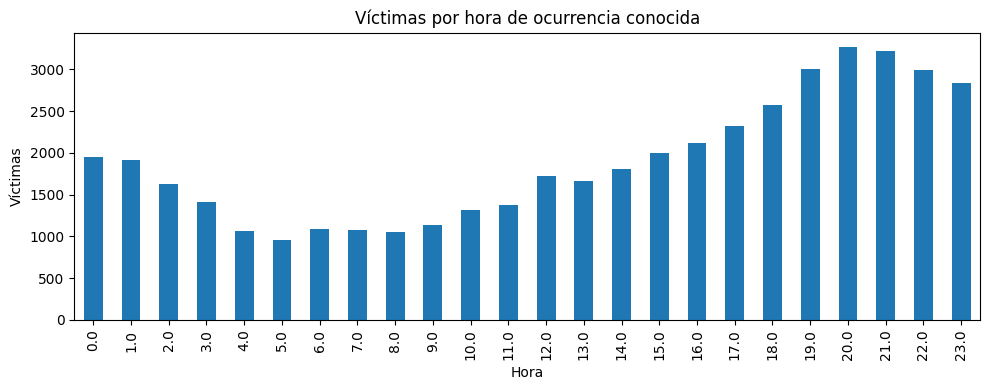

In [ ]:
victimas_diarias = (homicidios_validos.groupby(
    ["fecha_infraccion", "codigo_provincia", "provincia", "codigo_canton", "canton"])
    .size().reset_index(name="victimas_homicidio"))
assert victimas_diarias.victimas_homicidio.sum() == len(homicidios_validos)
display(victimas_diarias.head())
display(victimas_diarias.victimas_homicidio.describe())
display(victimas_diarias.nlargest(10, "victimas_homicidio"))
mensual = homicidios_validos.groupby(homicidios_validos.fecha_infraccion.dt.to_period("M")).size()
mensual.index = mensual.index.to_timestamp()
mensual.plot(figsize=(12,4), title="Víctimas registradas por mes", ylabel="Víctimas")
plt.tight_layout(); plt.show()
homicidios_validos.groupby(["provincia", "canton"]).size().nlargest(10).sort_values().plot.barh(
    figsize=(10,5), title="Cantones con más víctimas registradas")
plt.xlabel("Víctimas en el periodo disponible"); plt.tight_layout(); plt.show()
homicidios_validos.hora.value_counts().sort_index().plot.bar(
    figsize=(10,4), title="Víctimas por hora de ocurrencia conocida")
plt.xlabel("Hora"); plt.ylabel("Víctimas"); plt.tight_layout(); plt.show()


### Interpretación de resultados
Se obtuvieron **27.384** combinaciones de fecha y cantón con víctimas registradas. El **promedio** fue de **1,66 víctimas** por combinación, la **mediana** fue de **1** y el **máximo** fue de **12**5. Este promedio no representa todos los días del calendario, porque la tabla todavía no incluye los días sin registros.

La gráfica mensual muestra conteos relativamente bajos entre **2014** y **2020**, seguidos de un incremento marcado desde 2021. Los mayores picos se observan entre 2023 y 2025. Para identificar los meses exactos con mayores conteos se debe consultar la tabla mensual. El archivo de 2026 cubre únicamente enero a agosto, por lo que su total anual no es directamente comparable con años completos. Esto no significa que agosto sea un mes incompleto.
Guayaquil concentra el mayor número acumulado de víctimas, seguido de Quito y Durán. También destacan Machala, Esmeraldas y Manta. Estos resultados corresponden a cantidades absolutas; no permiten concluir qué cantón tiene mayor riesgo por habitante sin incorporar datos de población.
En la distribución por hora, los mayores conteos se observan alrededor de las 20:00 y 21:00, mientras que los menores aparecen aproximadamente entre las 04:00 y 08:00. La gráfica considera únicamente registros con hora conocida. Este patrón es descriptivo y no demuestra que el horario sea la causa de los homicidios.

El mayor conteo diario corresponde a Guayaquil, el 28 de septiembre de 2021, con 125 víctimas. También destacan Guayaquil el 12 de noviembre de 2021, con 65, y Santo Domingo el 9 de mayo de 2022, con 46. Estos valores deben revisarse en los registros originales y contrastarse con fuentes oficiales. No deben eliminarse automáticamente como valores atípicos, ya que un hecho puede involucrar múltiples víctimas.

La limpieza permitió reconocer valores como SIN_DATO y espacios vacíos como información faltante, normalizar textos y códigos territoriales y convertir las fechas y horas a formatos adecuados para el análisis. Los registros repetidos se conservaron porque, sin un identificador individual, no puede asegurarse que correspondan a errores y no a víctimas diferentes.
Las capturas no muestran el número de filas separadas ni el resultado de la revisión de códigos y categorías. Estos dos resultados deben completarse con las tablas de validación del notebook.

### 7 Preparación preliminar para Machine Learning
**y:** número de víctimas de homicidio intencional por cantón y día.

**X candidatas:** provincia y cantón como categorías, día de semana, mes, fin de semana y conteos históricos anteriores. Posteriormente se evaluarán feriados e historia del 911. El código cantonal es una clave territorial, no una cantidad numérica ordenada.

**Exclusiones:** atributos de la víctima y del hecho futuro, como edad, sexo, arma y motivación. No estarían disponibles antes de ese día. La hora sirve para explorar, pero la hora de un hecho futuro no se conoce.

No se entrenan modelos. Para crear rezagos se necesita un calendario diario completo confirmado por territorio; shift sobre días con registros omite días sin filas. El retraso de publicación debe considerarse antes de asumir disponibilidad del historial.

In [ ]:
victimas_diarias["dia_semana"] = victimas_diarias.fecha_infraccion.dt.dayofweek
victimas_diarias["mes"] = victimas_diarias.fecha_infraccion.dt.month
victimas_diarias["fin_semana"] = (victimas_diarias.dia_semana >= 5).astype(int)
display(victimas_diarias.head())
homicidios_validos.to_csv(carpeta_salida / "homicidios_unificados.csv.gz", index=False)
victimas_diarias.to_csv(carpeta_salida / "homicidios_conteos_diarios.csv.gz", index=False)
comparacion.to_csv(carpeta_salida / "comparacion_homicidios.csv", index=False)
rechazados[["fecha_infraccion", "provincia", "canton", "archivo_origen"]].to_csv(
    carpeta_salida / "homicidios_claves_rechazadas.csv", index=False)
print("Guardado en:", carpeta_salida)


,fecha_infraccion,codigo_provincia,provincia,codigo_canton,canton,victimas_homicidio,dia_semana,mes,fin_semana
0,2014-01-01,01,AZUAY,0101,CUENCA,1,2,1,0
1,2014-01-01,02,BOLÍVAR,0201,GUARANDA,1,2,1,0
2,2014-01-01,04,CARCHI,0401,TULCÁN,2,2,1,0
3,2014-01-01,06,CHIMBORAZO,0601,RIOBAMBA,1,2,1,0
4,2014-01-01,07,EL ORO,0712,SANTA ROSA,1,2,1,0


Guardado en: /content/drive/MyDrive/Resultados_911_Homicidios


### 8 Conclusión
## 8. Conclusión

Los datos permiten avanzar en el análisis del número de víctimas de homicidios intencionales por cantón y día. Se unificaron los archivos históricos y de 2026, se revisaron los valores faltantes y las posibles repeticiones, y se estandarizaron fechas, textos y códigos territoriales. Además, se generaron conteos diarios y variables de calendario: día de la semana, mes y fin de semana.

El análisis exploratorio mostró un incremento marcado de las víctimas registradas desde 2021 y una mayor concentración acumulada en Guayaquil. También se observaron diferencias según la hora de ocurrencia. Estos resultados describen los registros disponibles, pero no demuestran relaciones causales ni capacidad predictiva.

La variable objetivo propuesta es `victimas_homicidio`. Como variables candidatas se consideran el cantón y las características del calendario. Posteriormente, se evaluará incorporar feriados mediante una API y conteos históricos del ECU911, utilizando información disponible antes de la fecha que se desea predecir.

Las principales limitaciones son la cobertura de 2026 únicamente hasta agosto, los valores registrados como `SIN_DATO` y la necesidad de verificar conteos extremos y posibles repeticiones. Los días sin registros no deben considerarse automáticamente como días con cero víctimas sin confirmar la cobertura de la fuente.

En esta etapa se obtuvo una base preparada para continuar el proyecto. Antes de entrenar modelos será necesario verificar la cobertura, integrar las fuentes complementarias y definir una evaluación cronológica que permita comprobar si las variables seleccionadas ayudan a predecir los conteos futuros.

## Parte B Preparación opcional del ECU 911
Se procesa un archivo a la vez para ahorrar memoria. Se exportan conteos por fecha, provincia y cantón y un resumen de calidad por archivo. No se cargan todos los registros individuales simultáneamente. Comprueba que no existan copias del mismo mes: incluir ambas duplicaría sus conteos. Los resultados no prueban cobertura completa y no se rellenan días ausentes con cero.

No necesitas ejecutar esta parte para completar el análisis del dataset principal. Cuando la ejecutes, guarda la salida y úsala para la integración posterior.

In [ ]:
EJECUTAR_911 = False

In [ ]:
import re
import unicodedata

def normalizar_territorio(valor):
    if pd.isna(valor):
        return pd.NA
    texto = " ".join(str(valor).upper().split())
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))

def leer_911(archivo):
    if archivo.suffix.lower() == ".xlsx":
        df = pd.read_excel(archivo, dtype=str)
    else:
        try:
            df = pd.read_csv(archivo, sep=None, engine="python", dtype=str, encoding="utf-8-sig")
        except UnicodeDecodeError:
            df = pd.read_csv(archivo, sep=None, engine="python", dtype=str, encoding="latin1")
    df.columns = df.columns.str.strip()
    extras = [c for c in df.columns if c.startswith("Unnamed:")]
    df[extras] = df[extras].replace(r"^\s*$", pd.NA, regex=True)
    vacias = [c for c in extras if df[c].isna().all()]
    restantes = [c for c in extras if c not in vacias]
    if restantes:
        raise ValueError(f"{archivo.name}: revisa columnas adicionales {restantes}")
    return df.drop(columns=vacias), vacias

if EJECUTAR_911:
    archivos_911 = sorted(p for p in carpeta_911.iterdir()
                          if p.suffix.lower() in [".csv", ".xlsx"]
                          and p.name.lower().startswith(("emergencias_", "incidentes_")))
    if not archivos_911:
        raise ValueError("No se encontraron archivos del 911")
    partes_diarias, resumen_911, meses_leidos = [], [], set()
    for archivo in archivos_911:
        df, eliminadas = leer_911(archivo)
        if not {"Fecha", "provincia", "Canton"}.issubset(df.columns):
            raise ValueError(f"{archivo.name}: faltan fecha o territorio")
        fechas = pd.to_datetime(df.Fecha, format="mixed", dayfirst=True, errors="coerce")
        if df.empty or fechas.isna().any():
            raise ValueError(f"{archivo.name}: archivo vacío o fechas inválidas")
        periodos = fechas.dt.to_period("M").unique()
        if len(periodos) != 1:
            raise ValueError(f"{archivo.name}: revisa fechas de varios meses")
        if periodos[0] in meses_leidos:
            raise ValueError(f"Mes repetido {periodos[0]}: revisa copias antes de continuar")
        meses_leidos.add(periodos[0])
        df["fecha"] = fechas.dt.normalize()
        df["provincia"] = df.provincia.map(normalizar_territorio)
        df["canton"] = df.Canton.map(normalizar_territorio)
        df[["provincia", "canton"]] = df[["provincia", "canton"]].replace(
            {"": pd.NA, "SIN_DATO": pd.NA, "SIN DATO": pd.NA})
        validos = df.dropna(subset=["fecha", "provincia", "canton"])
        diario = validos.groupby(["fecha", "provincia", "canton"]).size().reset_index(name="incidentes_911")
        partes_diarias.append(diario)
        resumen_911.append({"archivo": archivo.name, "registros": len(df), "validos": len(validos),
                            "separados": len(df)-len(validos), "desde": fechas.min(), "hasta": fechas.max(),
                            "columnas_eliminadas": ", ".join(eliminadas)})
        print("Preparado:", archivo.name, "Filas originales:", len(df), "Filas agregadas:", len(diario))
    diario_911 = pd.concat(partes_diarias, ignore_index=True)
    assert not diario_911.duplicated(["fecha", "provincia", "canton"]).any()
    diario_911.to_csv(carpeta_salida / "ecu911_conteos_diarios.csv.gz", index=False)
    pd.DataFrame(resumen_911).to_csv(carpeta_salida / "resumen_911.csv", index=False)
    display(pd.DataFrame(resumen_911))
    display(diario_911.head())
else:
    print("Preparación del 911 omitida. Puedes continuar con el entregable de homicidios.")


Preparación del 911 omitida. Puedes continuar con el entregable de homicidios.


## Integración posterior
Lee homicidios_conteos_diarios.csv.gz y ecu911_conteos_diarios.csv.gz para evitar repetir la extracción. Normaliza ambos territorios con el mismo criterio y revisa equivalencias o un catálogo oficial. Integra solo después de definir el intervalo y los territorios con cobertura verificada. Utiliza una unión con validate="one_to_one" sobre fecha y territorio. Ausencias tras unir no equivalen automáticamente a cero. La API de feriados se añadirá posteriormente con fechas verificadas.

Los CSV comprimidos de conteos reducen volumen y no contienen atributos individuales de víctimas. El archivo de homicidios unificados conserva detalles para el trabajo interno; para compartir resultados utiliza los agregados.